In [4]:
import pandas as pd
from preprocessing import clean_data

In [5]:
raw_data = pd.read_csv('../data/spotify-tracks-dataset.csv')
df = clean_data(raw_data)

print("raw: ", raw_data.shape[0], " cleaned: ", df.shape[0])



raw:  114000  cleaned:  89740


In [6]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,genre_group
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,indie_folk
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,indie_folk
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,indie_folk
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,indie_folk
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,indie_folk


EDA + preprocessing + a working baseline, with early results. Multiple models trained (preliminary version).

In [7]:
df.info()

<class 'pandas.DataFrame'>
Index: 89740 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   track_id          89740 non-null  str    
 1   artists           89740 non-null  str    
 2   album_name        89740 non-null  str    
 3   track_name        89740 non-null  str    
 4   popularity        89740 non-null  int64  
 5   duration_ms       89740 non-null  int64  
 6   explicit          89740 non-null  bool   
 7   danceability      89740 non-null  float64
 8   energy            89740 non-null  float64
 9   key               89740 non-null  int64  
 10  loudness          89740 non-null  float64
 11  mode              89740 non-null  int64  
 12  speechiness       89740 non-null  float64
 13  acousticness      89740 non-null  float64
 14  instrumentalness  89740 non-null  float64
 15  liveness          89740 non-null  float64
 16  valence           89740 non-null  float64
 17  tempo   

In [8]:
df.describe()

,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,89740.000000,8.974000e+04,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000,89740.000000
mean,33.198808,2.291444e+05,0.562166,0.634458,5.283530,-8.498994,0.636973,0.087442,0.328285,0.173415,0.216971,0.469474,122.058134,3.897426
std,20.580640,1.129458e+05,0.176692,0.256606,3.559912,5.221518,0.480875,0.113278,0.338321,0.323849,0.194885,0.262864,30.117651,0.453437
min,0.000000,8.586000e+03,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,1.730400e+05,0.450000,0.457000,2.000000,-10.322250,0.000000,0.036000,0.017100,0.000000,0.098200,0.249000,99.262750,4.000000
50%,33.000000,2.132955e+05,0.576000,0.676000,5.000000,-7.185000,1.000000,0.048900,0.188000,0.000058,0.132000,0.457000,122.013000,4.000000
75%,49.000000,2.642930e+05,0.692000,0.853000,8.000000,-5.108000,1.000000,0.085900,0.625000,0.097625,0.279000,0.682000,140.077000,4.000000
max,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [9]:
df['track_genre'].unique().count()

np.int64(113)

In [10]:
df['genre_group'].unique().count()

np.int64(11)

In [11]:
df.columns

Index(['track_id', 'artists', 'album_name', 'track_name', 'popularity',
       'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness',
       'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness',
       'valence', 'tempo', 'time_signature', 'track_genre', 'genre_group'],
      dtype='str')

In [12]:
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,...,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,genre_group
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,...,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,indie_folk
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,...,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,indie_folk
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,...,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,indie_folk
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,...,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,indie_folk
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,...,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,indie_folk


In [ ]:
# Depreciated


# since there is only one null value row, it is best to just drop that
# old_len = df.shape[0]
# print(old_len)
# df = df.dropna()
# print(f"Number of dropped rows: {old_len - len(df)}")

89740
Number of dropped rows: 0


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df['genre_group'].value_counts()

genre_group
electronic_dance        19320
rock_metal              16843
pop                     10966
chill_jazz_classical    10380
latin                    9176
world                    7888
kids                     3948
hiphop_rnb               3851
country                  2925
indie_folk               2502
reggae                   1941
Name: count, dtype: int64

In [16]:
df['track_id'].value_counts()

track_id
5SuOikwiRyPMVoIQDJUgSV    1
4qPNDBW1i3p13qLCt0Ki3A    1
1iJBSr7s7jYXzM8EGcbK5b    1
6lfxq3CG4xtTiEg7opyCyx    1
5vjLSffimiIP26QG5WcN2K    1
                         ..
2C3TZjDRiAzdyViavDJ217    1
1hIz5L4IB9hN3WRYPOCGPw    1
6x8ZfSoqDjuNa5SVP5QjvX    1
2e6sXL2bYv4bSz6VTdnfLs    1
2hETkH7cOfqmz3LqZDHZf5    1
Name: count, Length: 89740, dtype: int64

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
df_danceability = df.groupby('genre_group')['danceability'].median()
df_danceability = df_danceability.sort_values(ascending=False)
df_danceability

genre_group
reggae                  0.6890
electronic_dance        0.6520
hiphop_rnb              0.6460
kids                    0.6385
latin                   0.6220
world                   0.5800
indie_folk              0.5610
pop                     0.5560
country                 0.5550
rock_metal              0.4870
chill_jazz_classical    0.4640
Name: danceability, dtype: float64

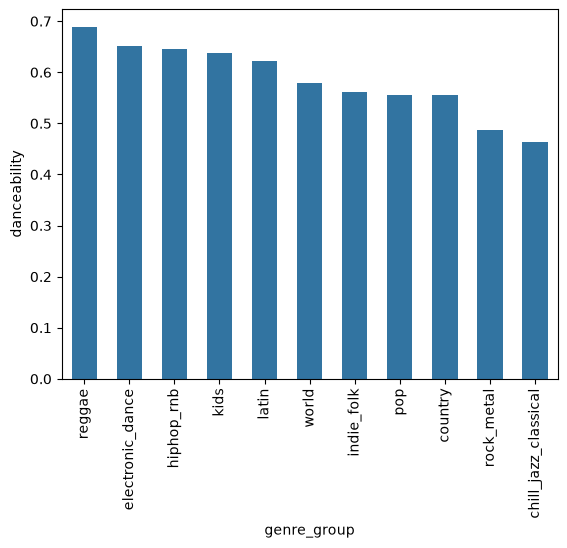

In [18]:
sns.barplot(df_danceability, gap=0.3)
plt.xticks(rotation="vertical")
plt.show()